# SageMaker Pipeline - OLX Smartphone Price Classifier

**Pós-Graduação em Business Analytics** (2024-25)

Identificação do grupo:

| nome | número de aluno |
|------|--------------|
|Ana Rita Maganinho|2180332|
|Bárbara Pedrosa|2240510|
|Liliana Gestosa|2240516|

## Projeto CCBA: Avaliação de Smartphones OLX
 
**Problema**: Quando colocamos um anúncio no OLX, muitos utilizadores enfrentam dificuldades em definir um preço adequado. A definição é feita de forma manual e subjetiva, baseada em percepções pessoais ou pesquisas pouco precisas, o que leva a preços desajustados e anúncios que permanecem online por longos períodos. Além disso, a falta de conhecimento técnico dificulta a correta categorização do equipamento.

**Solução**: A **SmartPrice** surge para resolver esta ineficiência. Através de uma interface simples e intuitiva, a ferramenta prevê a gama de preço (baixo, médio, alto, muito alto) de um telemóvel com base nas suas características técnicas, facilitando o processo de venda.

**Objetivo**: Desta forma, o principal objetivo da SmartPrice é prever automaticamente a gama de preço de um telemóvel, eliminando a subjetividade e acelerando o processo de venda no OLX. Assim, os anúncios convertem-se em vendas mais rápidas, otimizando a experiência do vendedor.

**Relevância**: A implementação desta ferramenta, torna a plataforma mais eficiente e atrativa, e por isso melhora a experiência do vendedor, acelera as vendas e reduz a carga nos servidores do OLX. 

# 1. Imports & Configuração AWS

In [29]:
!pip install --upgrade sagemaker

  Using cached sagemaker-2.246.0-py3-none-any.whl.metadata (17 kB)
  Using cached attrs-25.3.0-py3-none-any.whl.metadata (10 kB)
Using cached sagemaker-2.246.0-py3-none-any.whl (1.7 MB)
Using cached attrs-25.3.0-py3-none-any.whl (63 kB)
  Attempting uninstall: attrs
    Found existing installation: attrs 23.2.0
    Uninstalling attrs-23.2.0:
      Successfully uninstalled attrs-23.2.0
  Attempting uninstall: sagemaker
    Found existing installation: sagemaker 2.242.0
    Uninstalling sagemaker-2.242.0:
      Successfully uninstalled sagemaker-2.242.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sparkmagic 0.21.0 requires pandas<2.0.0,>=0.17.1, but you have pandas 2.2.3 which is incompatible.


In [1]:
import boto3
import os
import json
import logging
import warnings

import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

import sagemaker
from sagemaker.session import Session
from sagemaker.processing import ProcessingInput, ProcessingOutput
from sagemaker.sklearn.processing import SKLearnProcessor
from sagemaker.xgboost import XGBoost
from sagemaker.workflow.parameters import ParameterString, ParameterInteger, ParameterFloat
from sagemaker.workflow.steps import ProcessingStep, TrainingStep, CreateModelStep
from sagemaker.workflow.pipeline import Pipeline
from sagemaker.workflow.pipeline_context import PipelineSession
from sagemaker.workflow.step_collections import RegisterModel

# Suprimir warnings
logging.getLogger('matplotlib.category').setLevel(logging.WARNING)
warnings.simplefilter('ignore')

/opt/conda/lib/python3.12/site-packages/pydantic/_internal/_fields.py:192: UserWarning: Field name "json" in "MonitoringDatasetFormat" shadows an attribute in parent "Base"
  warnings.warn(


sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


In [2]:
# Configuração AWS

def get_sm_session_and_role():
    session = sagemaker.Session()
    role = sagemaker.get_execution_role()
    region = session.boto_region_name
    bucket = 'ccba-smartprice'
    prefix = 'price_range'
    print(f"SageMaker Role: {role}")
    print(f"SageMaker Bucket: {bucket}")
    print(f"AWS Region: {region}")
    return session, role, bucket, prefix

session, role, bucket, prefix = get_sm_session_and_role()
sm_pipeline_session = PipelineSession()

# S3 URIs
raw_key = "Dados_projeto.csv"
data_uri = f"s3://{bucket}/Dados_projeto.csv"
processed_data_uri = f"s3://{bucket}/{prefix}/processed-data"
model_output_uri = f"s3://{bucket}/{prefix}/model"
evaluation_output_uri = f"s3://{bucket}/{prefix}/evaluation"

SageMaker Role: arn:aws:iam::058264123587:role/LabRole
SageMaker Bucket: ccba-smartprice
AWS Region: us-east-1


In [3]:
# verificar ficheiro no bucket

s3 = boto3.client('s3')
try:
    s3.head_object(Bucket=bucket, Key=raw_key)
    print(f"O ficheiro '{raw_key}' existe no bucket '{bucket}'.")
except s3.exceptions.ClientError as e:
    if e.response['Error']['Code'] == '404':
        print(f"ERRO: O ficheiro '{raw_key}' NÃO foi encontrado no bucket '{bucket}'.")
    else:
        print(f"ERRO: Ocorreu um erro ao verificar o ficheiro: {e}")

O ficheiro 'Dados_projeto.csv' existe no bucket 'ccba-smartprice'.


# 2. Carregar Dados & Análise Exploratória (EDA)

Nesta secção, carregamos o CSV a partir do S3 para realizar EDA localmente, antes de construir o pipeline. Mantemos a coluna `smart_id` só para mostrar que será removida logo no pipeline.

Resumo das 22 variáveis do dataset:

- **smart_id:** Identificador único para cada smartphone.
- **battery_power:** Capacidade da bateria em mAh, indicando a duração aproximada do smartphone.
- **blue:** Indica se o smartphone possui Bluetooth (0 para não, 1 para sim).
- **clock_speed:** Velocidade de execução de instruções do microprocessador em GHz.
- **dual_sim:** Indica se o smartphone suporta dois cartões SIM (0 para não, 1 para sim).
- **fc:** Resolução da câmara frontal em megapixels.
- **four_g:** Indica se o smartphone tem conectividade 4G (0 para não, 1 para sim).
- **int_memory:** Tamanho do armazenamento físico interno em Gigabytes.
- **m_dep:** Profundidade do smartphone em centímetros.
- **mobile_wt:** Peso do smartphone em gramas.
- **n_cores:** Número de núcleos do processador.
- **pc:** Resolução da câmara principal em megapixels.
- **px_height:** Resolução em pixels da altura do ecrã.
- **px_width:** Resolução em pixels da largura do ecrã.
- **ram:** Memória de Acesso Aleatório (RAM) em Megabytes.
- **sc_h:** Altura da tela do smartphone em centímetros.
- **sc_w:** Largura da tela do smartphone em centímetros.
- **talk_time:** Duração da bateria em horas durante chamadas com carga completa.
- **three_g:** Indica se o smartphone tem conectividade 3G (0 para não, 1 para sim).
- **touch_screen:** Indica se o smartphone possui ecrã tátil (0 para não, 1 para sim).
- **wifi:** Indica se o smartphone tem capacidade WiFi (0 para não, 1 para sim).
- **price_range:** Variável alvo que classifica a gama de preço do smartphone em 0 (baixo custo), 1 (custo médio), 2 (custo elevado) e 3 (custo muito elevado).

Outras informações a destacar:
* **Total de Observações:** Existem 2000 observações no dataset.
* **Disstribuição da Variável Alvo:** Cada uma das 4 categorias da variável price_range possui 500 observações, o que representa 25% do total para cada categoria.

In [4]:
# carregar dados

df = pd.read_csv(data_uri)
df.head()

,smart_id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,786078.0,842.0,0.0,2.2,0.0,1.0,0.0,7.0,0.6,188.0,...,20.0,756.0,2549.0,9.0,7.0,19.0,0.0,0.0,1.0,1.0
1,534544.0,1021.0,1.0,0.5,1.0,0.0,1.0,53.0,0.7,136.0,...,905.0,1988.0,2631.0,17.0,3.0,7.0,1.0,1.0,0.0,2.0
2,686124.0,563.0,1.0,0.5,1.0,2.0,1.0,41.0,0.9,145.0,...,1263.0,1716.0,2603.0,11.0,2.0,9.0,1.0,1.0,0.0,2.0
3,785858.0,615.0,1.0,2.5,0.0,0.0,0.0,10.0,0.8,131.0,...,1216.0,1786.0,2769.0,16.0,8.0,11.0,1.0,0.0,0.0,2.0
4,858689.0,1821.0,1.0,1.2,0.0,13.0,1.0,44.0,0.6,141.0,...,1208.0,1212.0,1411.0,8.0,2.0,15.0,1.0,1.0,0.0,1.0


In [5]:
# estatísticas e nulos
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
smart_id,2000.0,500859.78800,292824.070282,242.0,249195.00,497081.0,759487.25,999996.0
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0


In [9]:
# remover duplicados e linhas onde TODOS os valores são nulos (em branco) em uma única sequência
df = df.drop_duplicates().dropna(how='all')
print("Dimensões após remover duplicados e linhas em branco:", df.shape)
print("\nContagem de missing values por coluna:")
display(df.isnull().sum())

Dimensões após remover duplicados e linhas em branco: (2000, 22)

Contagem de missing values por coluna:


smart_id         0
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

price_range
1.0    500
2.0    500
3.0    500
0.0    500
Name: count, dtype: int64

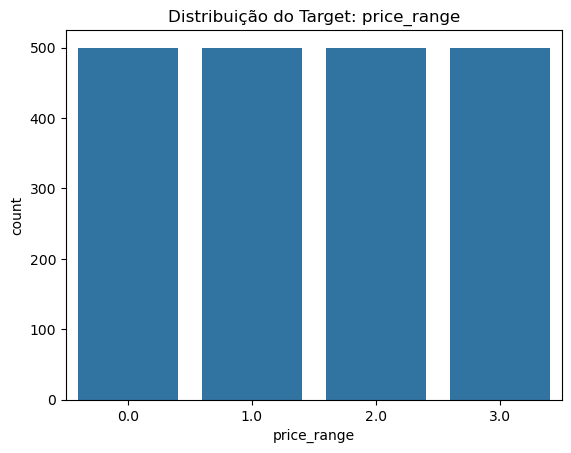

In [10]:
# contagem das categorias alvo (price_range)

display(df["price_range"].value_counts())

sns.countplot(x='price_range', data=df)
plt.title("Distribuição do Target: price_range")
plt.show()


Distribuição das características numéricas:


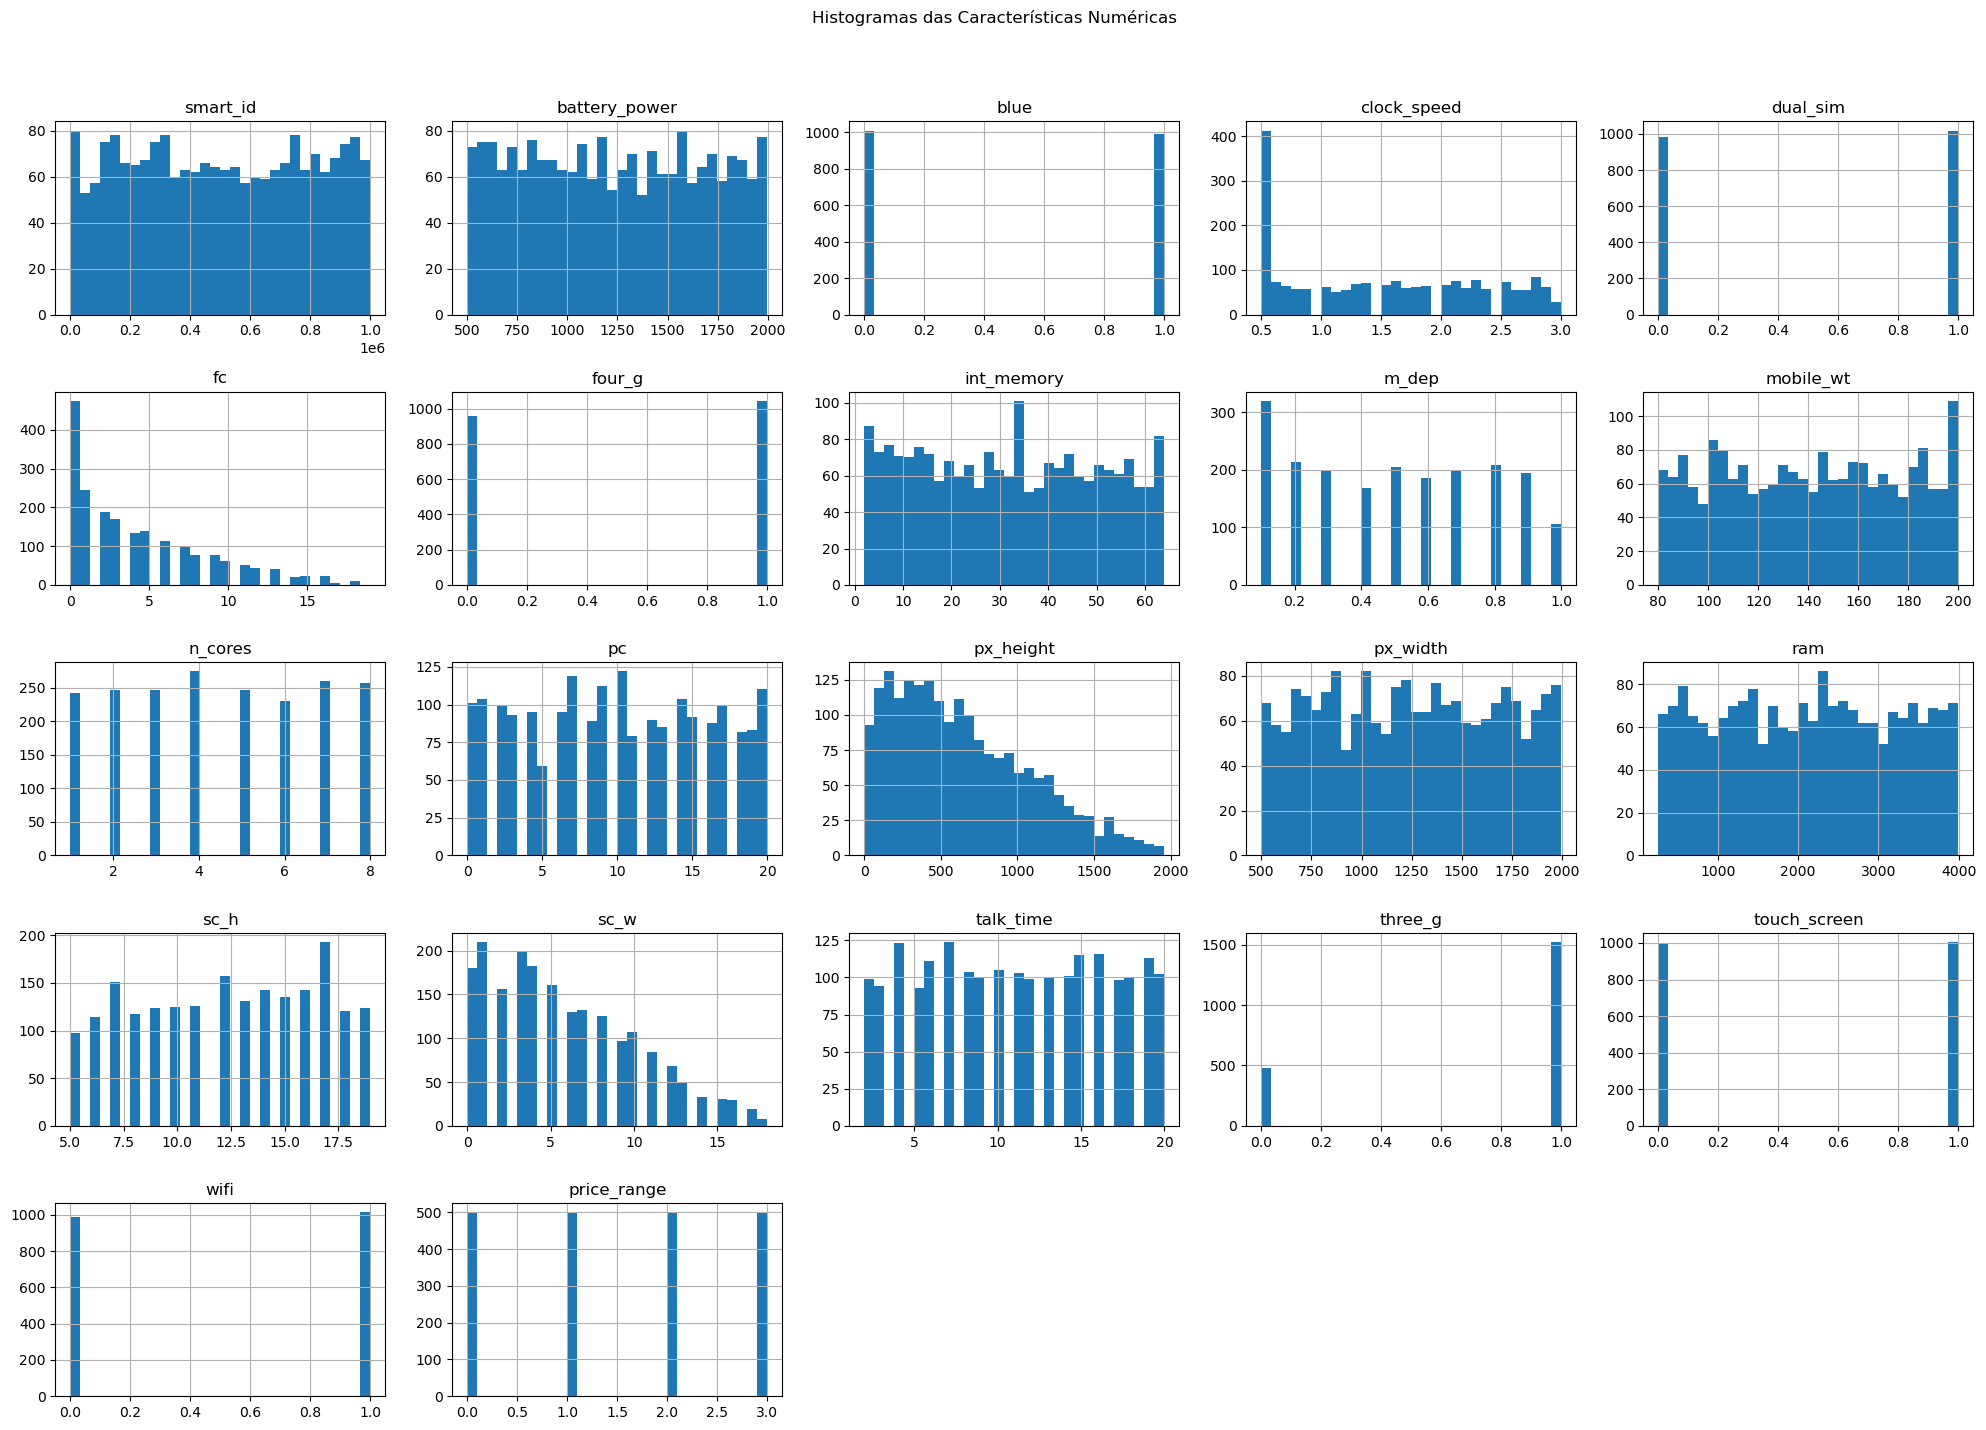

In [11]:
# Visualizar distribuições das características numéricas

print("\nDistribuição das características numéricas:")
df.hist(bins=30, figsize=(20, 15))
plt.suptitle('Histogramas das Características Numéricas')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 2.1. Correlações iniciais
Vamos verificar a correlação das variáveis originais com o target (sem as novas features ainda).


Matriz de Correlação:


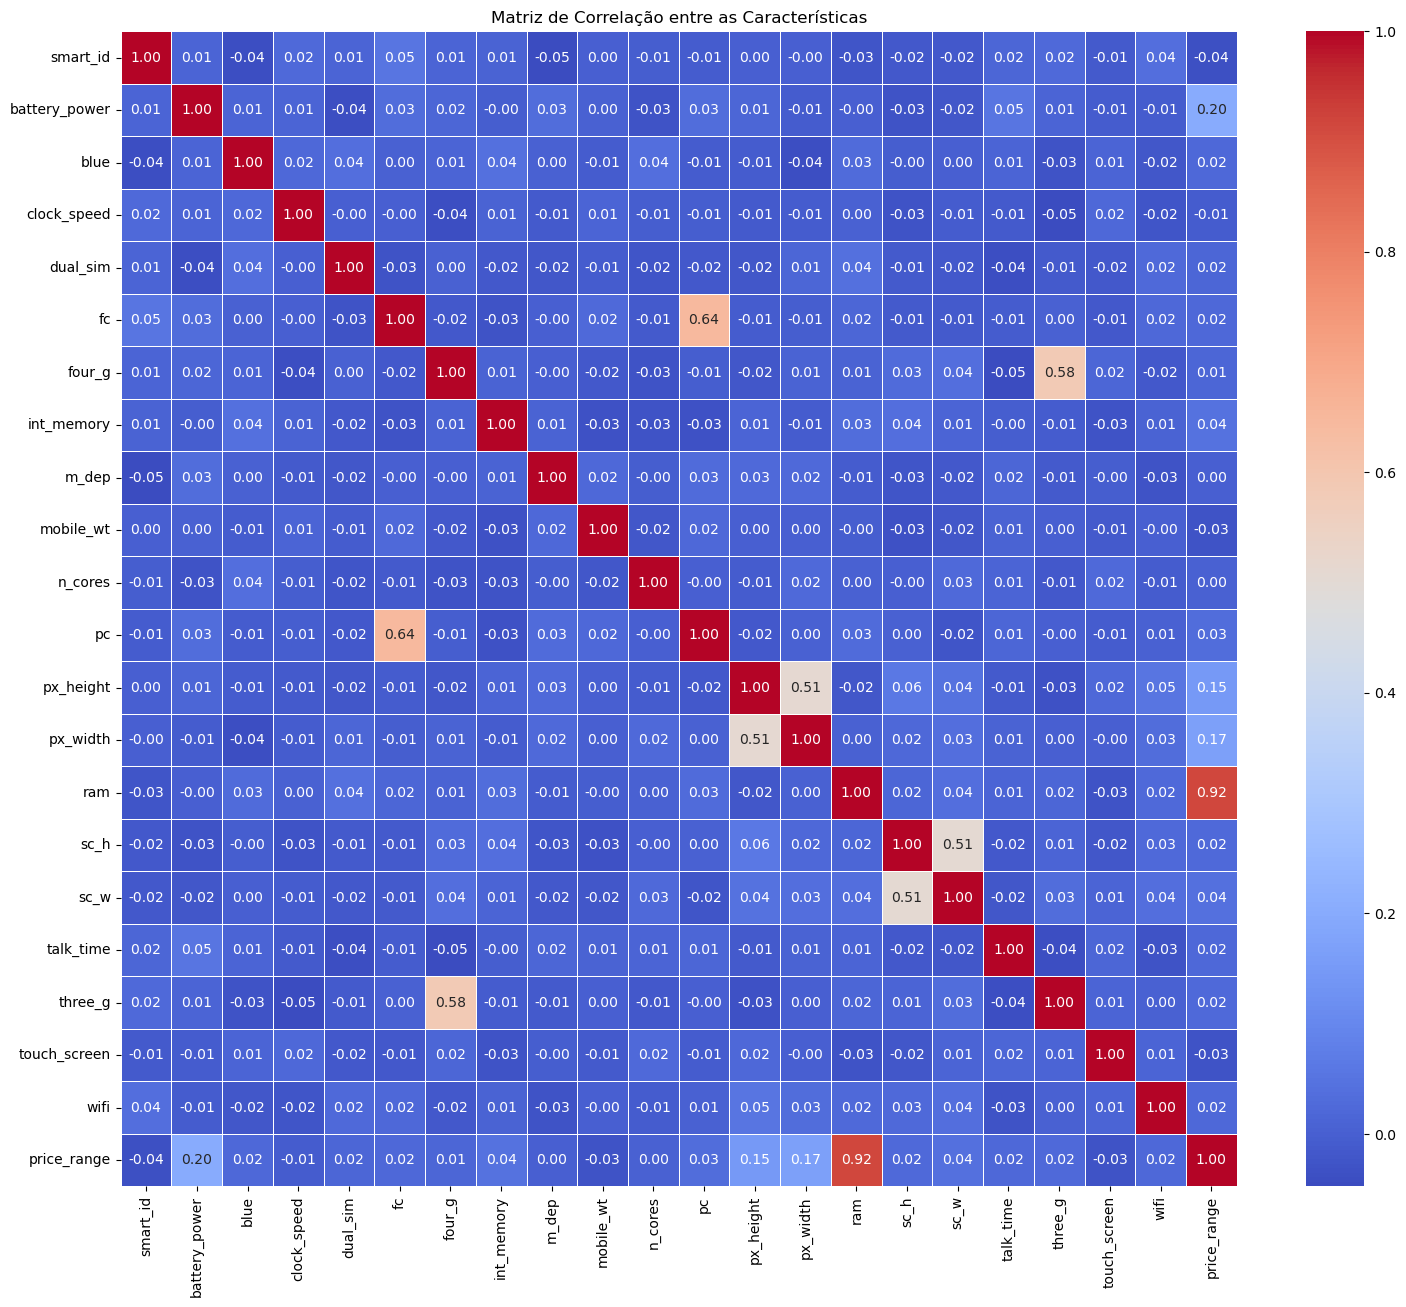

In [12]:
# Correlation matrix
print("\nMatriz de Correlação:")
plt.figure(figsize=(18, 15))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlação entre as Características')
plt.show()


Relação entre RAM, Battery Power e Price Range:


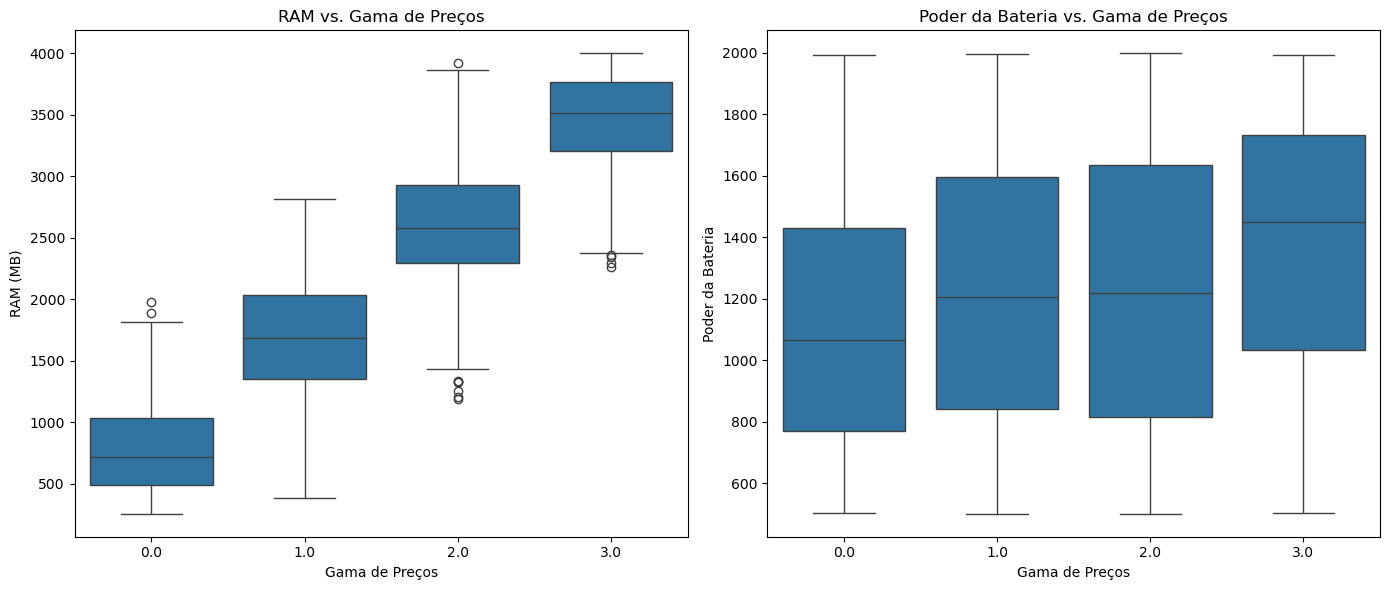

In [14]:
# Visualização da Relação entre Features Chave e price_range (ex: RAM e battery_power)
print("\nRelação entre RAM, Battery Power e Price Range:")
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.boxplot(x='price_range', y='ram', data=df)
plt.title('RAM vs. Gama de Preços')
plt.xlabel('Gama de Preços')
plt.ylabel('RAM (MB)')

plt.subplot(1, 2, 2)
sns.boxplot(x='price_range', y='battery_power', data=df)
plt.title('Poder da Bateria vs. Gama de Preços')
plt.xlabel('Gama de Preços')
plt.ylabel('Poder da Bateria')
plt.tight_layout()
plt.show()


Distribuição de Características Binárias por Gama de Preços:


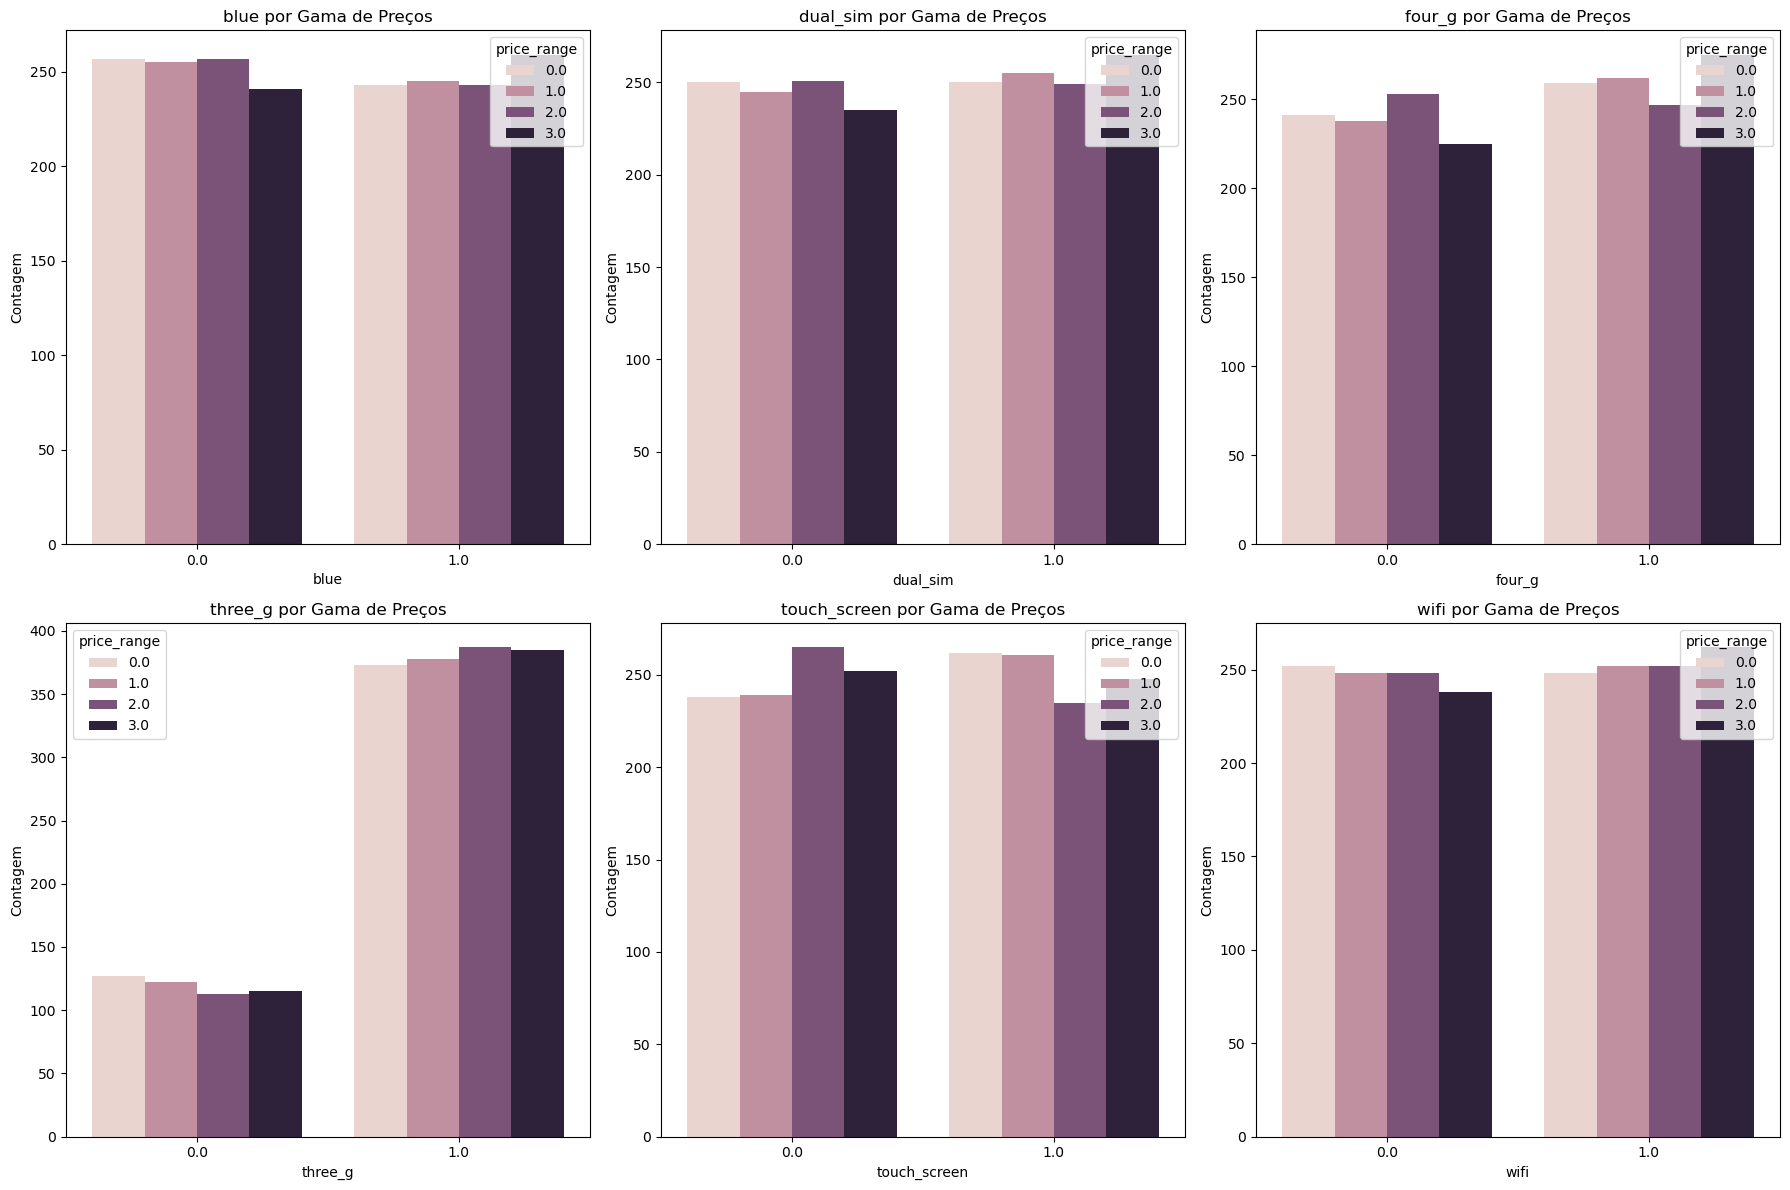

In [15]:
# Visualizar características binárias (ex: blue, dual_sim, four_g, three_g, touch_screen, wifi)

binary_features = ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi']
print("\nDistribuição de Características Binárias por Gama de Preços:")
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
for i, feature in enumerate(binary_features):
    sns.countplot(x=feature, hue='price_range', data=df, ax=axes[i])
    axes[i].set_title(f'{feature} por Gama de Preços')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Contagem')
plt.tight_layout()
plt.show()

# 3. Feature Engineering 

A criação de novas features é necessária para:

* Enriquecer o dataset: Fornecer ao modelo informações mais complexas e inter-relacionadas que podem não ser evidentes nas features originais.
* Melhorar o desempenho do modelo: Capturar relações não lineares e padrões nos dados que podem levar a previsões mais precisas.
* Aumentar a capacidade de generalização: Permitir que o modelo aprenda características mais abstratas dos smartphones, melhorando a sua capacidade de prever a gama de preços em dados não vistos.

**Funcionalidades novas adicionadas**:
1. Criação de novas features:
   - `screen_area = sc_h * sc_w`
   - `pixel_density = sqrt(px_width² + px_height²) / screen_area`
   - `ram_per_core = ram / n_cores`
   - `camera_total = pc + fc`
   - `weight_to_battery_ratio = mobile_wt / battery_power`
2. Combinação de perfis:
   - `has_connectivity = blue + wifi + three_g + four_g`
   - `advanced_features = touch_screen + dual_sim`

In [16]:
fe_df = df.copy()
fe_df['screen_area'] = fe_df['sc_h'] * fe_df['sc_w']
fe_df['pixel_density'] = np.sqrt(fe_df['px_height']**2 + fe_df['px_width']**2) / (fe_df['screen_area'] + 1e-6)
fe_df['ram_per_core'] = fe_df['ram'] / (fe_df['n_cores'] + 1e-6)
fe_df['camera_total'] = fe_df['pc'] + fe_df['fc']
fe_df['weight_to_battery_ratio'] = fe_df['mobile_wt'] / (fe_df['battery_power'] + 1e-6)
fe_df['has_connectivity'] = fe_df[['blue', 'wifi', 'three_g', 'four_g']].sum(axis=1)
fe_df['advanced_features'] = fe_df[['touch_screen', 'dual_sim']].sum(axis=1)

display(fe_df.head())

,smart_id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,touch_screen,wifi,price_range,screen_area,pixel_density,ram_per_core,camera_total,weight_to_battery_ratio,has_connectivity,advanced_features
0,786078.0,842.0,0.0,2.2,0.0,1.0,0.0,7.0,0.6,188.0,...,0.0,1.0,1.0,63.0,12.004198,1274.499363,3.0,0.223278,1.0,0.0
1,534544.0,1021.0,1.0,0.5,1.0,0.0,1.0,53.0,0.7,136.0,...,1.0,0.0,2.0,51.0,42.829422,876.999708,6.0,0.133203,3.0,2.0
2,686124.0,563.0,1.0,0.5,1.0,2.0,1.0,41.0,0.9,145.0,...,1.0,0.0,2.0,22.0,96.849382,520.599896,8.0,0.257549,3.0,2.0
3,785858.0,615.0,1.0,2.5,0.0,0.0,0.0,10.0,0.8,131.0,...,0.0,0.0,2.0,128.0,16.880157,461.499923,9.0,0.213008,2.0,0.0
4,858689.0,1821.0,1.0,1.2,0.0,13.0,1.0,44.0,0.6,141.0,...,1.0,0.0,1.0,16.0,106.950040,705.499647,27.0,0.077430,3.0,1.0



Distribuição das Novas Características (Feature Engineering):


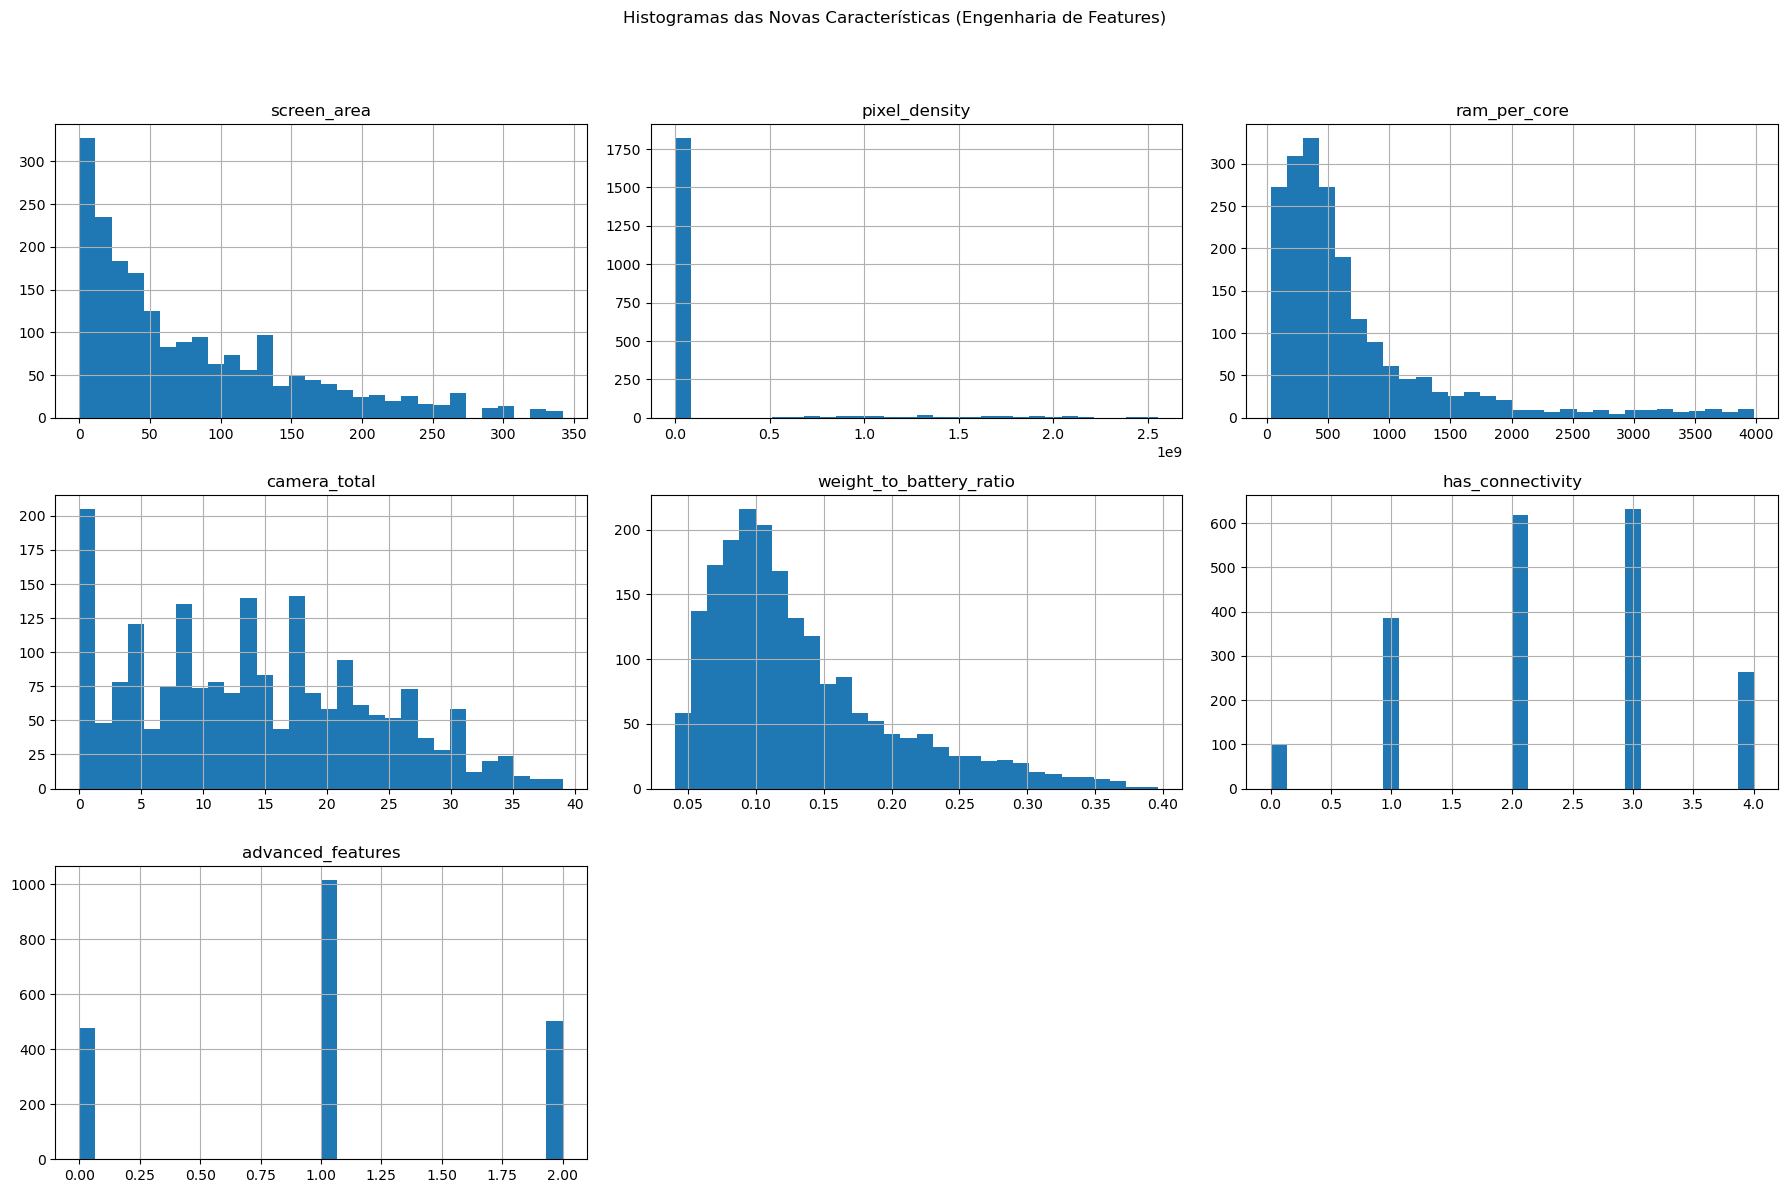

In [17]:
# List of the new features you created
new_features = [
    'screen_area',
    'pixel_density',
    'ram_per_core',
    'camera_total',
    'weight_to_battery_ratio',
    'has_connectivity',
    'advanced_features'
]

# Select only the new features from your DataFrame
new_features_df = fe_df[new_features]

print("\nDistribuição das Novas Características (Feature Engineering):")
new_features_df.hist(bins=30, figsize=(18, 12))
plt.suptitle('Histogramas das Novas Características (Engenharia de Features)', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) 
plt.show()

# 4. Definição da Pipeline SageMaker

A criação de um pipeline é crucial para automatizar e otimizar o ciclo de vida do modelo de Machine Learning. Garante repetibilidade, escalabilidade e uma melhor gestão. A pipeline assenta nos seguintes passos:

* **Definição de Parâmetros:** Configurações de entrada e saída são definidas como parâmetros para flexibilidade.
* **Pré-processamento de Dados (`PreprocessStep`):** Uma fase essencial onde o `preprocess.py` é executado para carregar o dataset, limpar dados, criar novas features através de engenharia de features (e.g., screen_area, pixel_density, ram_per_core), e dividir os dados em conjuntos de treino, validação e teste de forma estratificada. Os dados processados são salvos no S3.
* **Treino do Modelo (`XGBoostTrainStep`):** O script `train.py` utiliza os dados de treino e validação para treinar um modelo XGBoostClassifier. As importâncias das features são calculadas, salvas e enviadas para o S3.
* **Avaliação do Modelo (`EvaluationStep`):** O script `evaluate.py` avalia o modelo treinado usando o conjunto de teste, calculando métricas como accuracy, relatório de classificação e matriz de confusão. Os resultados são gravados num ficheiro JSON.
* **Registo do Modelo (`RegisterModelStep`):** O modelo treinado é registado no SageMaker Model Registry, permitindo a sua versão e gestão centralizada.
* **Definição da Pipeline Completa (`SmartphonePriceRangePipeline`):** Todos os passos são orquestrados numa sequência, garantindo o fluxo automático de dados e modelos entre cada fase do pipeline.

In [18]:
# Parâmetros da pipeline

input_data_param = ParameterString(name="InputDataUri", default_value=data_uri)
output_data_param = ParameterString(name="ProcessedDataUri", default_value=processed_data_uri)
model_output_param = ParameterString(name="ModelOutputUri", default_value=model_output_uri)

### 4.1. Preprocessing (`preprocess.py`)

In [19]:
# 4.1 Script de processamento (preprocess.py)

processing_script = 'preprocess.py'
with open(processing_script, 'w') as f:
    f.write(r"""
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split

# Caminhos dos arquivos montados pelo ProcessingStep
input_file = '/opt/ml/processing/input/Dados_projeto.csv'
output_base = '/opt/ml/processing'

# Leitura do CSV
try:
    df = pd.read_csv(input_file)
except Exception as e:
    raise RuntimeError(f"Falha ao ler arquivo: {e}")

df = df.drop_duplicates().dropna(how='all')

df = df.drop('smart_id', axis=1, errors='ignore')

# Feature engineering
df['screen_area'] = df['sc_h'] * df['sc_w']
df['pixel_density'] = np.sqrt(df['px_height']**2 + df['px_width']**2) / (df['screen_area'] + 1e-6)
df['ram_per_core'] = df['ram'] / (df['n_cores'] + 1e-6)
df['camera_total'] = df['pc'] + df['fc']
df['weight_to_battery_ratio'] = df['mobile_wt'] / (df['battery_power'] + 1e-6)
df['has_connectivity'] = df[['blue','wifi','three_g','four_g']].sum(axis=1)
df['advanced_features'] = df[['touch_screen','dual_sim']].sum(axis=1)

# Divisão estratificada
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df['price_range'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['price_range'], random_state=42)

# Salvar arquivos
os.makedirs(f"{output_base}/train", exist_ok=True)
os.makedirs(f"{output_base}/validation", exist_ok=True)
os.makedirs(f"{output_base}/test", exist_ok=True)

train_df.to_csv(f"{output_base}/train/train.csv", index=False)
val_df.to_csv(f"{output_base}/validation/validation.csv", index=False)
test_df.to_csv(f"{output_base}/test/test.csv", index=False)
""")

# 4.2 Parâmetros de input/output para usar no pipeline
from sagemaker.workflow.parameters import ParameterString

# input_data_param = ParameterString(name="InputDataUri", default_value=data_uri)
# output_data_param = ParameterString(name="ProcessedData", default_value="s3://ccba-smartprice/processed/")
# training_input_uri = ParameterString(name="TrainingInput", default_value="s3://ccba-smartprice/processed/train/")
# validation_input_uri = ParameterString(name="ValidationInput", default_value="s3://ccba-smartprice/processed/validation/")
# test_input_uri = ParameterString(name="TestInput", default_value="s3://ccba-smartprice/processed/test/")

# 4.3 Definição do ProcessingStep
from sagemaker.sklearn.processing import SKLearnProcessor
from sagemaker.workflow.steps import ProcessingStep
from sagemaker.processing import ProcessingInput, ProcessingOutput

sklearn_processor = SKLearnProcessor(
    framework_version='1.0-1',
    role=role,
    instance_type='ml.m5.xlarge',
    instance_count=1,
    base_job_name='ccba-preprocess',
    sagemaker_session=sm_pipeline_session
)

processing_step = ProcessingStep(
    name='PreprocessStep',
    processor=sklearn_processor,
    inputs=[
        ProcessingInput(source=input_data_param, destination='/opt/ml/processing/input')
    ],
    outputs=[
        ProcessingOutput(source='/opt/ml/processing/train', output_name='train_data'),
        ProcessingOutput(source='/opt/ml/processing/validation', output_name='validation_data'),
        ProcessingOutput(source='/opt/ml/processing/test', output_name='test_data')
    ],
    code=processing_script
)

print("Passo de pré-processamento definido com treino, validação e teste.")

[06/13/25 14:19:53] INFO     Defaulting to only available Python version: py3                     ]8;id=474045;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py\image_uris.py]8;;\:]8;id=832332;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py#610\610]8;;\

Passo de pré-processamento definido com treino, validação e teste.


### 4.2. Treino (`train.py`)

In [20]:
# 4.2 Script de treino (train.py) 

training_script = 'train.py'
with open(training_script, 'w') as f:
    f.write(r"""
import pandas as pd
import xgboost as xgb
import os
import matplotlib.pyplot as plt
import json
import boto3

# Puxando bucket e prefixo do ambiente
bucket = os.environ['BUCKET']
prefix = os.environ['PREFIX']

# Caminhos dos datasets
train_path = '/opt/ml/input/data/train/train.csv'
val_path   = '/opt/ml/input/data/validation/validation.csv'
model_output     = '/opt/ml/model'
output_data_dir  = os.environ.get('SM_OUTPUT_DATA_DIR', '/opt/ml/output/data')

# Carregar dados
train_df = pd.read_csv(train_path)
val_df   = pd.read_csv(val_path)

X_train = train_df.drop('price_range', axis=1)
y_train = train_df['price_range']
X_val   = val_df.drop('price_range', axis=1)
y_val   = val_df['price_range']

# Treinar modelo
model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=4,
    max_depth=5,
    learning_rate=0.2,
    n_estimators=100
)
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    early_stopping_rounds=10,
    verbose=True
)

# Salvar modelo
os.makedirs(model_output, exist_ok=True)
model.save_model(os.path.join(model_output, 'xgboost-model'))

# --- Feature Importances ---
feature_importances = model.feature_importances_
feature_names       = X_train.columns
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# 1) SALVAR CSV de importâncias
os.makedirs(output_data_dir, exist_ok=True)
csv_path = os.path.join(output_data_dir, 'feature_importances.csv')
importance_df.to_csv(csv_path, index=False)
print(f"Feature importances saved to: {csv_path}")

# 2) SALVAR PLOT de importâncias
plt.figure(figsize=(12, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plot_path = os.path.join(output_data_dir, 'feature_importance_plot.png')
plt.savefig(plot_path)
print(f"Feature importance plot saved to: {plot_path}")

# 3) UPLOAD manual para um prefix separado (artifacts/)
s3 = boto3.client('s3')
for fname in ['feature_importances.csv', 'feature_importance_plot.png']:
    local = os.path.join(output_data_dir, fname)
    s3.upload_file(local, bucket, f'{prefix}/artifacts/{fname}')
    print(f"Uploaded {fname} to s3://{bucket}/{prefix}/artifacts/{fname}")
""")

# Agora, quando você construir o estimator, injete as env vars:
# 4) TrainingStep
xgb_estimator = XGBoost(
    entry_point='train.py',
    framework_version='1.5-1',
    role=role,
    instance_count=1,
    instance_type='ml.m5.xlarge',
    output_path=model_output_param,
    sagemaker_session=sm_pipeline_session,
    base_job_name='smartprice-xgb-train',
    environment={'BUCKET': bucket, 'PREFIX': prefix}
)

from sagemaker.inputs import TrainingInput

training_step = TrainingStep(
    name='XGBoostTrainStep',
    estimator=xgb_estimator,
    inputs={
        'train': TrainingInput(
            s3_data=processing_step.properties.ProcessingOutputConfig.Outputs['train_data'].S3Output.S3Uri,
            content_type='text/csv'
        ),
        'validation': TrainingInput(
            s3_data=processing_step.properties.ProcessingOutputConfig.Outputs['validation_data'].S3Output.S3Uri,
            content_type='text/csv'
        )
    }
)

print("Passo de treino definido.")

[06/13/25 14:19:57] INFO     Ignoring unnecessary Python version: py3.                            ]8;id=890675;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py\image_uris.py]8;;\:]8;id=134686;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py#603\603]8;;\

                    INFO     Ignoring unnecessary instance type: ml.m5.xlarge.                    ]8;id=487498;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py\image_uris.py]8;;\:]8;id=704374;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py#530\530]8;;\

Passo de treino definido.


### 4.3 Script de avaliação (`evaluate.py`)

In [21]:
# 4.3 Script de avaliação (evaluate.py) 

from sagemaker.processing import ScriptProcessor, ProcessingInput, ProcessingOutput
from sagemaker.workflow.steps import ProcessingStep
from sagemaker import image_uris
import os, stat

# 1) Gerar o evaluate.py
evaluation_script = 'evaluate.py'
with open(evaluation_script, 'w') as f:
    f.write(r"""
#!/usr/bin/env python3
import pandas as pd
import numpy as np
import json
import os
import tarfile
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

test_path = '/opt/ml/processing/test/test.csv'
model_path = '/opt/ml/processing/model'

# Carregar dados de teste
df = pd.read_csv(test_path)
X = df.drop('price_range', axis=1)
y = df['price_range']

# Extrair e carregar modelo
with tarfile.open(os.path.join(model_path, 'model.tar.gz'), 'r:gz') as tar:
    tar.extractall(path=model_path)

model = xgb.XGBClassifier()
model.load_model(os.path.join(model_path, 'xgboost-model'))

# Avaliação
y_pred = model.predict(X)
acc = accuracy_score(y, y_pred)
report = classification_report(y, y_pred, output_dict=True)
cm = confusion_matrix(y, y_pred)

# Guardar resultados
output_dir = '/opt/ml/processing/evaluation'
os.makedirs(output_dir, exist_ok=True)
metrics = {
    'metrics': {
        'accuracy': {'value': acc},
        'classification_report': report,
        'confusion_matrix': cm.tolist()
    }
}
with open(os.path.join(output_dir, 'evaluation.json'), 'w') as fout:
    json.dump(metrics, fout)
""")

# 2) (Opcional) chmod +x
st = os.stat(evaluation_script)
os.chmod(evaluation_script, st.st_mode | stat.S_IEXEC)

# 3) Obter a imagem XGBoost e instanciar o ScriptProcessor COM command
region    = sm_pipeline_session.boto_region_name
xgb_image = image_uris.retrieve(
    framework='xgboost',
    region=region,
    version='1.5-1'
)

script_processor = ScriptProcessor(
    image_uri=xgb_image,
    role=role,
    instance_count=1,
    instance_type='ml.m5.xlarge',
    command=["python3", "/opt/ml/processing/input/code/evaluate.py"],
    base_job_name='ccba-evaluate',
    sagemaker_session=sm_pipeline_session
)

# 4) Gerar os argumentos do step — note que não há source_dir nem entrypoint aqui
step_args = script_processor.run(
    code=evaluation_script,
    inputs=[
        ProcessingInput(source=processing_step.properties.ProcessingOutputConfig.Outputs['test_data'].S3Output.S3Uri,
                        destination='/opt/ml/processing/test'),
        ProcessingInput(source=training_step.properties.ModelArtifacts.S3ModelArtifacts,
                        destination='/opt/ml/processing/model')
    ],
    outputs=[
        ProcessingOutput(source='/opt/ml/processing/evaluation',
                         output_name='evaluation',
                         destination=evaluation_output_uri)
    ]
)

# 5) Criar o ProcessingStep com esses step_args
evaluation_step = ProcessingStep(
    name='EvaluationStep',
    step_args=step_args
)

print("Passo de avaliação do modelo definido.")

[06/13/25 14:20:09] INFO     Ignoring unnecessary instance type: None.                            ]8;id=419683;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py\image_uris.py]8;;\:]8;id=461349;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py#530\530]8;;\

Passo de avaliação do modelo definido.


### 4.4. Criar modelo

In [22]:
# 4.4 último passo: criar modelo

from sagemaker.workflow.model_step import ModelStep
from sagemaker.xgboost.model import XGBoostModel

xgb_model = XGBoostModel(
    model_data=training_step.properties.ModelArtifacts.S3ModelArtifacts,
    role=role,
    framework_version='1.5-1',
    sagemaker_session=sm_pipeline_session
)

model_registration_step = ModelStep(
    name='RegisterModelStep',
    step_args=xgb_model.create(instance_type='ml.m5.xlarge')
)

print("Passo de criação do modelo definido.")

[06/13/25 14:20:15] INFO     Ignoring unnecessary instance type: ml.m5.xlarge.                    ]8;id=220243;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py\image_uris.py]8;;\:]8;id=877793;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py#530\530]8;;\

Passo de criação do modelo definido.


### 4.5. Definir Pipeline

In [23]:
# 4.5 Pipeline Definition

pipeline = Pipeline(
    name='SmartphonePriceRangePipeline',
    parameters=[
        input_data_param,
        output_data_param,
        model_output_param
    ],
    steps=[
        processing_step,
        training_step,
        evaluation_step,
        model_registration_step
    ],
    sagemaker_session=sm_pipeline_session
)

print("Pipeline definida.")

Pipeline definida.


# 5. Criação e Execução da Pipeline

Um diagrama visual da pipeline implementada: 

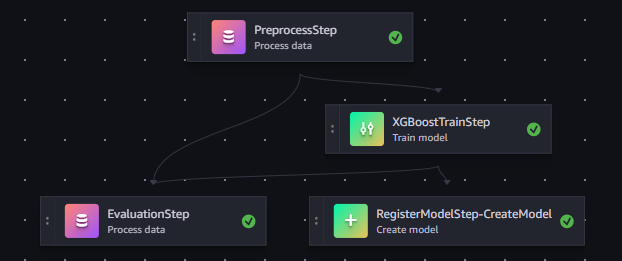

In [24]:
# Criar/Atualizar pipeline

pipeline.upsert(role_arn=role)

[06/13/25 14:20:43] WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=443991;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=265511;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

[06/13/25 14:20:44] WARNING  Popping out 'TrainingJobName' from the pipeline definition by default ]8;id=134625;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=610859;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             since it will be overridden at pipeline execution time. Please                        
                             utilize the PipelineDefinitionConfig to persist this field in the                     
                             pipeline definition if desired.                                                       

                    WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=196169;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=557720;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

                    WARNING  Popping out 'ModelName' from the pipeline definition by default since ]8;id=977001;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=626813;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             it will be overridden at pipeline execution time. Please utilize the                  
                             PipelineDefinitionConfig to persist this field in the pipeline                        
                             definition if desired.                                                                

                    WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=118467;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=509273;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

                    WARNING  Popping out 'TrainingJobName' from the pipeline definition by default ]8;id=416262;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=811998;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             since it will be overridden at pipeline execution time. Please                        
                             utilize the PipelineDefinitionConfig to persist this field in the                     
                             pipeline definition if desired.                                                       

                    WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=862303;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=42745;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

                    WARNING  Popping out 'ModelName' from the pipeline definition by default since ]8;id=190776;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py\utilities.py]8;;\:]8;id=608027;file:///opt/conda/lib/python3.12/site-packages/sagemaker/workflow/utilities.py#465\465]8;;\
                             it will be overridden at pipeline execution time. Please utilize the                  
                             PipelineDefinitionConfig to persist this field in the pipeline                        
                             definition if desired.                                                                

{'PipelineArn': 'arn:aws:sagemaker:us-east-1:058264123587:pipeline/SmartphonePriceRangePipeline',
 'ResponseMetadata': {'RequestId': '0dd071d4-59c5-408f-8453-7b81a3b078ae',
  'HTTPStatusCode': 200,
  'HTTPHeaders': {'x-amzn-requestid': '0dd071d4-59c5-408f-8453-7b81a3b078ae',
   'content-type': 'application/x-amz-json-1.1',
   'content-length': '96',
   'date': 'Fri, 13 Jun 2025 14:20:44 GMT'},
  'RetryAttempts': 0}}

In [25]:
# Executar pipeline
execution = pipeline.start()
print(f"Pipeline execution Arn: {execution.arn}")

# Aguardar término da pipeline
execution.wait()
print("Pipeline concluída com status:", execution.describe()['PipelineExecutionStatus'])

Pipeline execution Arn: arn:aws:sagemaker:us-east-1:058264123587:pipeline/SmartphonePriceRangePipeline/execution/eg82hdsk6jdw
Pipeline concluída com status: Succeeded


# 6. Deploy do Modelo e Teste de Inferência em Tempo Real

In [26]:
from sagemaker.session import Session as SageSession
from sagemaker.xgboost import XGBoostModel
from botocore.exceptions import ClientError

# Extrair TrainingJobName e S3 URI do modelo 
steps = execution.list_steps()
train_step = next((s for s in steps if s["StepName"] == "XGBoostTrainStep"), None)
if train_step is None:
    raise RuntimeError("XGBoostTrainStep não encontrada em execution.list_steps()")

# Obter o nome do job de treino
train_job_name = train_step["Metadata"]["TrainingJob"].get("TrainingJobName") \
                 or train_step["Metadata"]["TrainingJob"]["Arn"].split("/")[-1]
print(f"Training job: {train_job_name}")

# Descrever o job para obter o S3 URI do artefacto
sm_client = session.boto_session.client("sagemaker")
model_artifact = sm_client.describe_training_job(
    TrainingJobName=train_job_name
)["ModelArtifacts"]["S3ModelArtifacts"]
print(f"Model artifact URI: {model_artifact}")

# Instanciar o XGBoostModel localmente 
xgb_model = XGBoostModel(
    model_data=model_artifact,
    role=role,                    
    framework_version="1.5-1",
    sagemaker_session=session
)

# 4) Deploy do endpoint 
try:
    predictor = xgb_model.deploy(
        initial_instance_count=1,
        instance_type="ml.m5.xlarge",
        endpoint_name="price-range-endpoint"
    )
    print(f"Endpoint criado: {predictor.endpoint_name}")
except ClientError as e:
    if e.response["Error"]["Code"] == "AccessDeniedException":
        print(
            "Erro de permissão ao criar endpoint: verifique se a role do SageMaker "
            "tem as ações 'sagemaker:CreateEndpointConfig' e 'sagemaker:CreateEndpoint'."
        )
    else:
        raise

print("\nFim do deploy do modelo.")

Training job: pipelines-eg82hdsk6jdw-XGBoostTrainStep-AJZReehRBR
Model artifact URI: s3://ccba-smartprice/price_range/model/pipelines-eg82hdsk6jdw-XGBoostTrainStep-AJZReehRBR/output/model.tar.gz


[06/13/25 14:39:26] INFO     Ignoring unnecessary instance type: ml.m5.xlarge.                    ]8;id=967898;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py\image_uris.py]8;;\:]8;id=772285;file:///opt/conda/lib/python3.12/site-packages/sagemaker/image_uris.py#530\530]8;;\

                    INFO     Creating model with name: sagemaker-xgboost-2025-06-13-14-39-26-586    ]8;id=420836;file:///opt/conda/lib/python3.12/site-packages/sagemaker/session.py\session.py]8;;\:]8;id=320824;file:///opt/conda/lib/python3.12/site-packages/sagemaker/session.py#4094\4094]8;;\

[06/13/25 14:39:27] INFO     Creating endpoint-config with name price-range-endpoint                ]8;id=865225;file:///opt/conda/lib/python3.12/site-packages/sagemaker/session.py\session.py]8;;\:]8;id=913363;file:///opt/conda/lib/python3.12/site-packages/sagemaker/session.py#5937\5937]8;;\

                    INFO     Creating endpoint with name price-range-endpoint                       ]8;id=765404;file:///opt/conda/lib/python3.12/site-packages/sagemaker/session.py\session.py]8;;\:]8;id=418879;file:///opt/conda/lib/python3.12/site-packages/sagemaker/session.py#4759\4759]8;;\

------!Endpoint criado: price-range-endpoint

Fim do deploy do modelo.


In [27]:
# Teste rápido

from sagemaker.serializers import CSVSerializer
from sagemaker.deserializers import CSVDeserializer
from IPython.display import display, Markdown

if 'predictor' in locals():
    display(Markdown(f"### Amostra a testar:\n"))
    df_sample = fe_df.drop(['price_range', 'smart_id'], axis=1).sample(1)
    sample_index = df_sample.index[0]
    true_class = fe_df.loc[sample_index, 'price_range']
    print("Amostra (index =", sample_index, "): ")
    display(df_sample)
    display(Markdown(f"\n### Teste em tempo real:"))

    # Preparar payload e obter predição
    predictor.serializer = CSVSerializer()
    predictor.deserializer = CSVDeserializer()
    payload = df_sample.to_csv(header=False, index=False)
    result = predictor.predict(payload)

    # Converter resultado em probabilidades e classe
    probs = list(map(float, result[0]))
    pred_class = int(np.argmax(probs))
    print(f"Probabilidades por classe: {probs}")
    print(f"Classe prevista: {pred_class}")
    print(f"Classe verdadeira: {true_class}")
    if pred_class == true_class:
        print("Previsão correta! 🎉")
    else:
        print("Previsão incorreta.")

    print("Fim do Teste de Inferência em Tempo Real")

### Amostra a testar:


Amostra (index = 1323 ): 


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,three_g,touch_screen,wifi,screen_area,pixel_density,ram_per_core,camera_total,weight_to_battery_ratio,has_connectivity,advanced_features
1323,712.0,0.0,0.5,0.0,6.0,0.0,27.0,0.5,86.0,2.0,...,1.0,1.0,1.0,110.0,16.422888,1000.4995,17.0,0.120787,2.0,1.0



### Teste em tempo real:

Probabilidades por classe: [0.00015005555178504437, 0.9838116765022278, 0.015911953523755074, 0.00012629138655029237]
Classe prevista: 1
Classe verdadeira: 1.0
Previsão correta! 🎉
Fim do Teste de Inferência em Tempo Real


# 7. Avaliação Detalhada do Modelo (fora da Pipeline para visualização)

Arquivo baixado em evaluation.json


### Classification Report (Accuracy: 0.9333)

,precision,recall,f1-score,support
0.0,1.000000,0.946667,0.972603,75.000000
1.0,0.923077,0.960000,0.941176,75.000000
2.0,0.893333,0.893333,0.893333,75.000000
3.0,0.921053,0.933333,0.927152,75.000000
accuracy,0.933333,0.933333,0.933333,0.933333
macro avg,0.934366,0.933333,0.933566,300.000000
weighted avg,0.934366,0.933333,0.933566,300.000000



### Matriz de Confusão

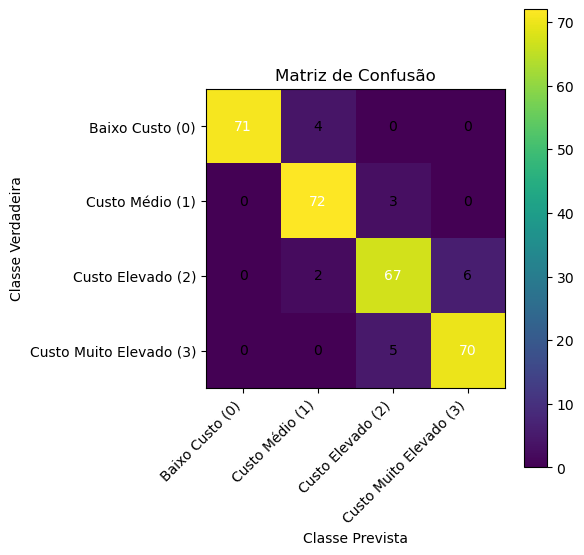

In [28]:
# Configurações e download do evaluation.json

import boto3
import json
import os

evaluation_output_uri = "s3://ccba-smartprice/price_range/evaluation"  

bucket = evaluation_output_uri.split("/")[2]
prefix = "/".join(evaluation_output_uri.split("/")[3:]) + "/evaluation.json"

s3 = boto3.client("s3")
local_path = "evaluation.json"
s3.download_file(bucket, prefix, local_path)
print(f"Arquivo baixado em {local_path}")

# Carregar resultados e preparar tabelas 
import numpy as np
import pandas as pd

with open(local_path, "r") as f:
    results = json.load(f)

accuracy = results["metrics"]["accuracy"]["value"]
report_dict = results["metrics"]["classification_report"]
cm = np.array(results["metrics"]["confusion_matrix"])

# DataFrame do classification report
df_report = pd.DataFrame(report_dict).transpose()

# Exibir classification report
display(Markdown(f"### Classification Report (Accuracy: {accuracy:.4f})"))
display(df_report)

display(Markdown(f"\n### Matriz de Confusão"))
# Plotar matriz de confusão com matplotlib
import matplotlib.pyplot as plt

classes = ['Baixo Custo (0)', 'Custo Médio (1)', 'Custo Elevado (2)', 'Custo Muito Elevado (3)']

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(cm, interpolation="nearest")
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(len(classes)),
    yticks=np.arange(len(classes)),
    xticklabels=classes,
    yticklabels=classes,
    ylabel="Classe Verdadeira",
    xlabel="Classe Prevista",
    title="Matriz de Confusão"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Anotar valores na matriz
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, cm[i, j],
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black"
        )

plt.tight_layout()
plt.show()


### Feature Importances: Top 10

Top 10 Features:


,Feature,Importance
0,ram,0.345135
1,battery_power,0.094875
2,weight_to_battery_ratio,0.072280
3,px_width,0.067732
4,px_height,0.063275
5,blue,0.034543
6,ram_per_core,0.030303
7,int_memory,0.025960
8,advanced_features,0.022579
9,m_dep,0.022017



### Feature Importances: Plot

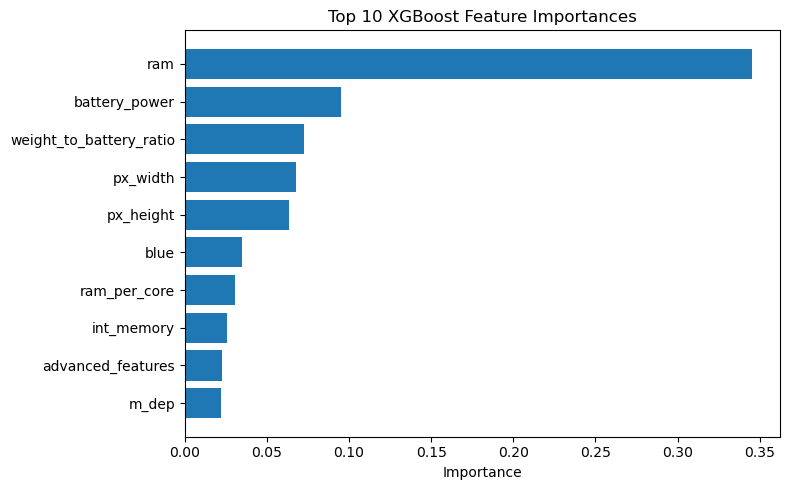

In [29]:
# 1) CSV de importâncias

# Parâmetros para caminho do S3 (os mesmos da pipeline)
bucket = 'ccba-smartprice'
prefix = 'price_range'
importance_scores_key = f'{prefix}/artifacts/feature_importances.csv'
obj = s3.get_object(Bucket=bucket, Key=importance_scores_key)
importance_df = pd.read_csv(obj['Body'])

# 2) mostrar top 10 de features com maior importância

display(Markdown(f"\n### Feature Importances: Top 10"))
top10 = importance_df.nlargest(10, 'Importance').reset_index(drop=True)
print("Top 10 Features:")
display(top10)

# 3) plot das features com maior importância

display(Markdown(f"\n### Feature Importances: Plot"))
plt.figure(figsize=(8, 5))
plt.barh(top10['Feature'], top10['Importance'])
plt.gca().invert_yaxis()    # para a mais importante ficar no topo
plt.xlabel("Importance")
plt.title("Top 10 XGBoost Feature Importances")
plt.tight_layout()
plt.show()

# 8. Aplicação Streamlit 

Chegámos ao fim da exploração técnica do nosso pipeline de Machine Learning. 
Agora, convidamo-lo a ver o verdadeiro impacto e a experiência de utilizador da SmartPrice na sua versão interativa.

A aplicação Streamlit permite-lhe simular a sugestão de preços em tempo real, como um vendedor OLX.

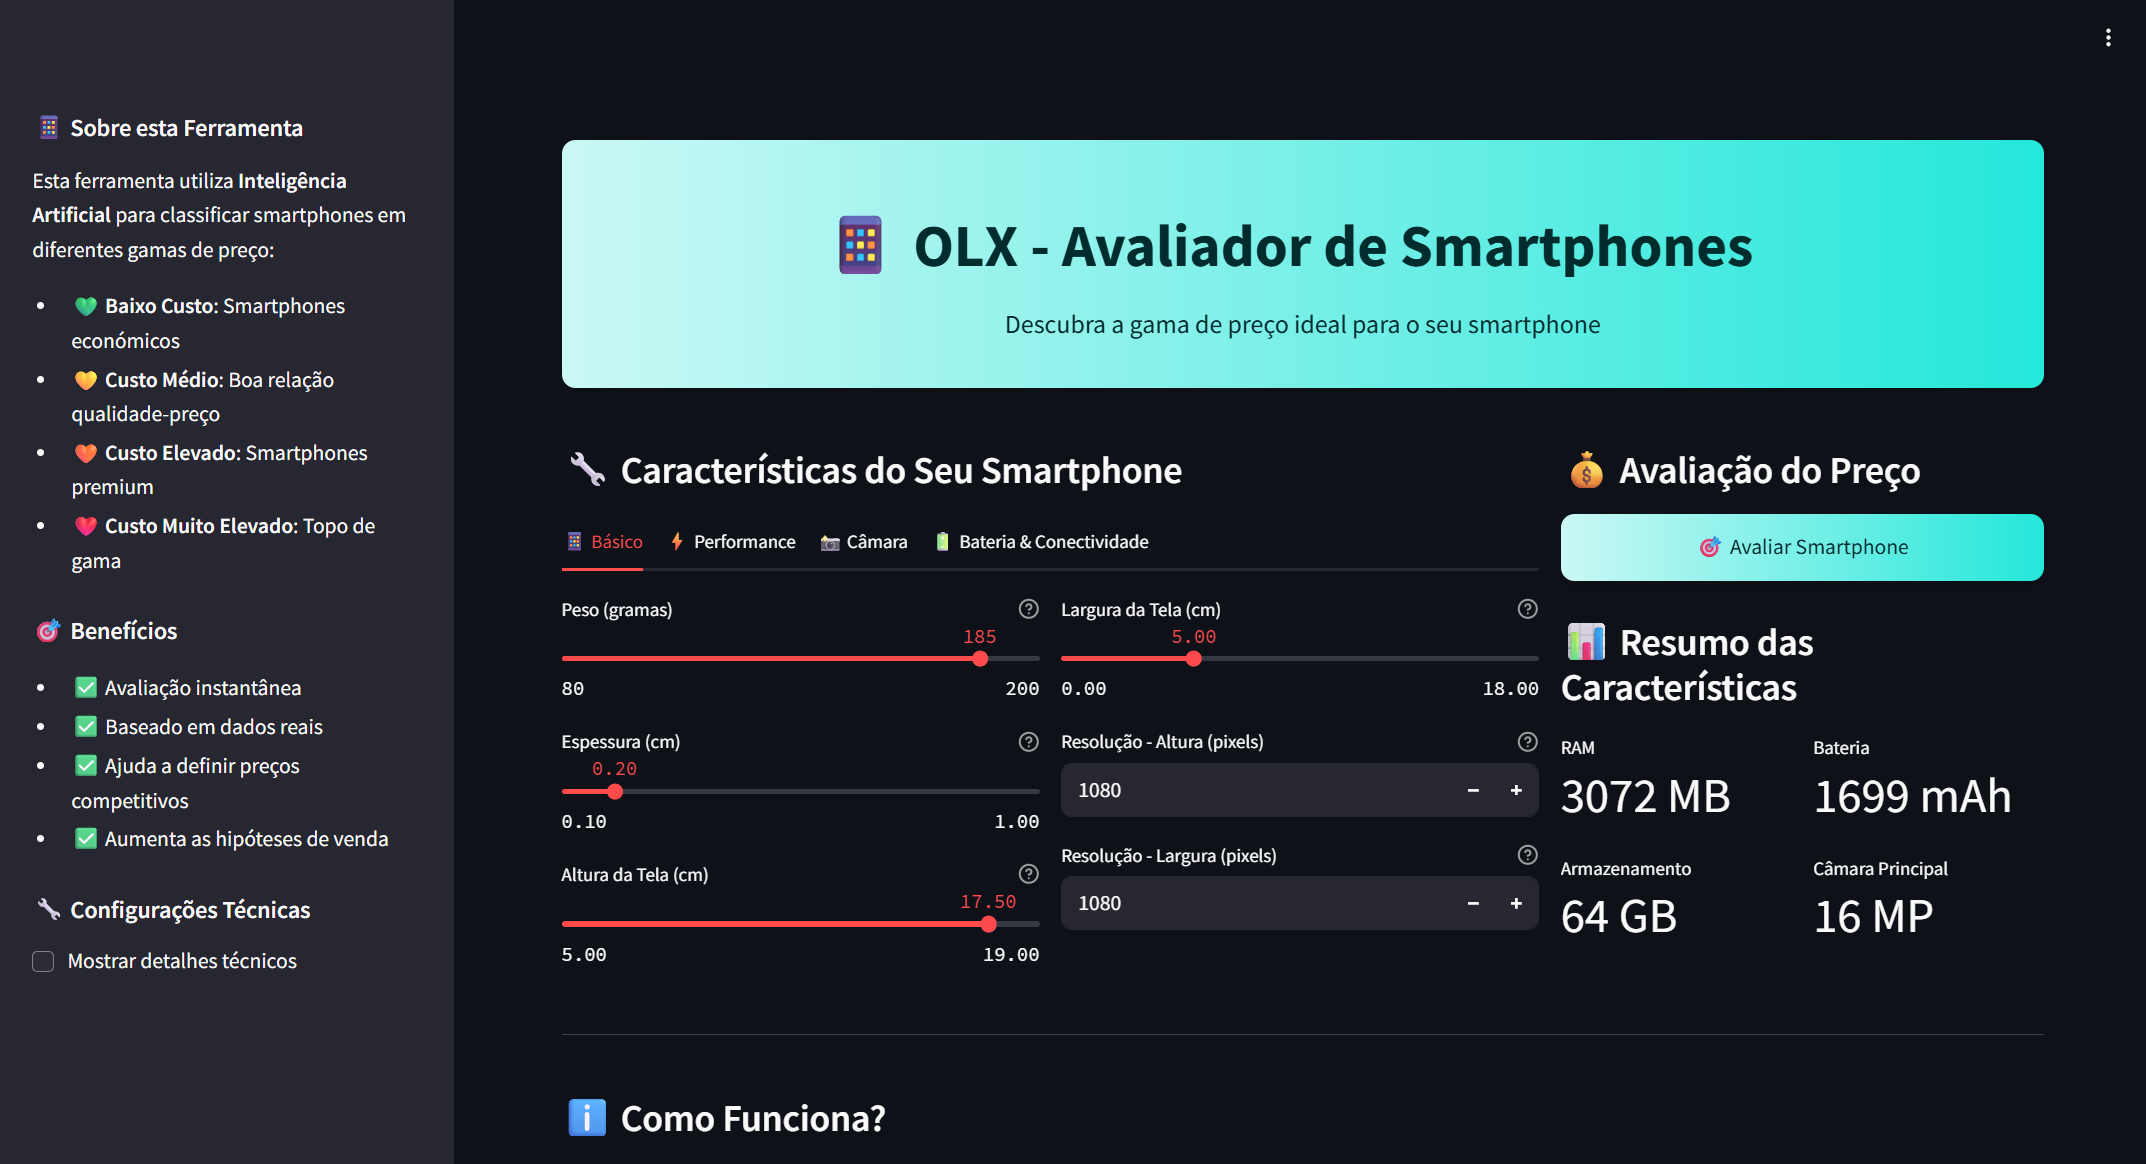

Para aceder e experimentar a plataforma, basta seguir estes passos simples:

* Certifique-se de que tem o ficheiro `streamlit_app_olx.py` no mesmo diretório deste notebook.
* Abra o seu terminal e navegue até esse diretório.
* Execute os seguintes comandos:
    * `pip install streamlit`
    * `streamlit run streamlit_app_olx.py`

Sinta-se à vontade para explorar a SmartPrice e ver como a nossa solução pode transformar a experiência de precificação de smartphones!

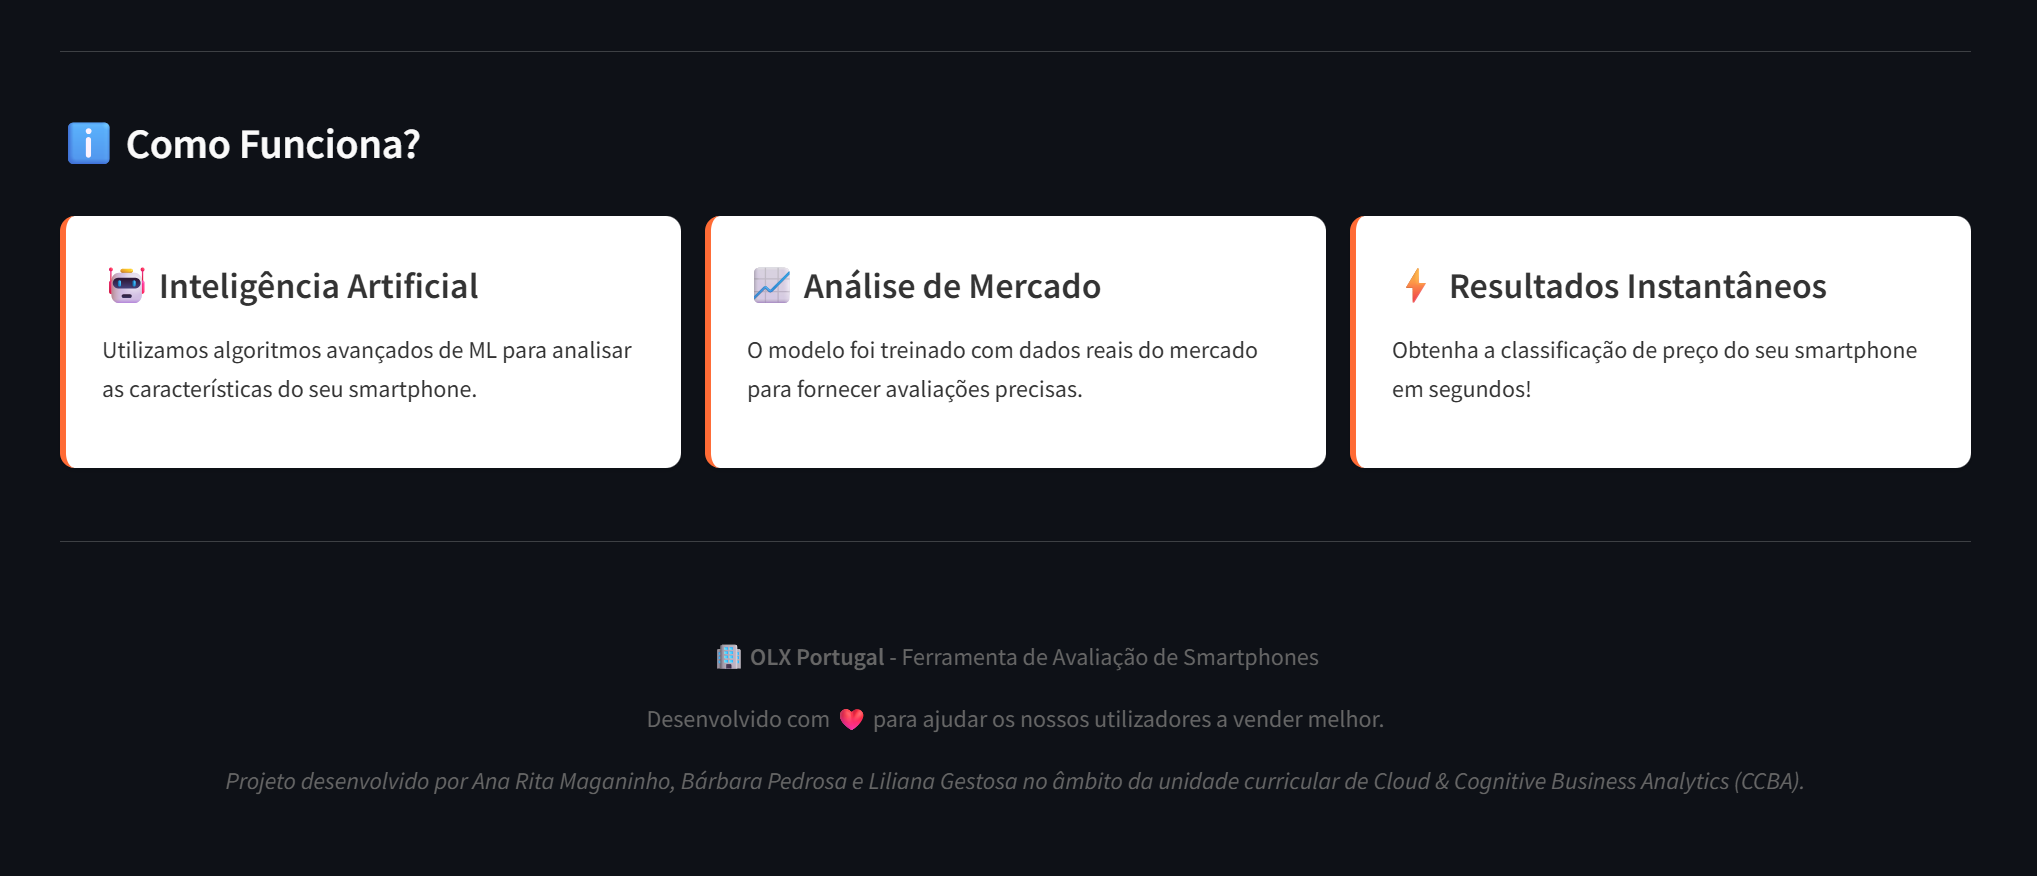

# 9. Cleanup (Opcional)

Após terminar o teste, pode eliminar o endpoint e o modelo associado para evitar custos desnecessários:

In [ ]:
# predictor.delete_endpoint()
# predictor.delete_model()
# session.delete_endpoint(predictor.endpoint_name)

# 10. Próximos Passos e Conclusões

Chegamos ao fim da nossa exploração do pipeline SmartPrice. O nosso objetivo é que esta solução evolua para um ecossistema MLOps plenamente automatizado, cobrindo todo o ciclo de vida do modelo. Isto garantirá a sua sustentabilidade, precisão contínua e adaptação às dinâmicas do mercado, mantendo um valor inestimável para a OLX.

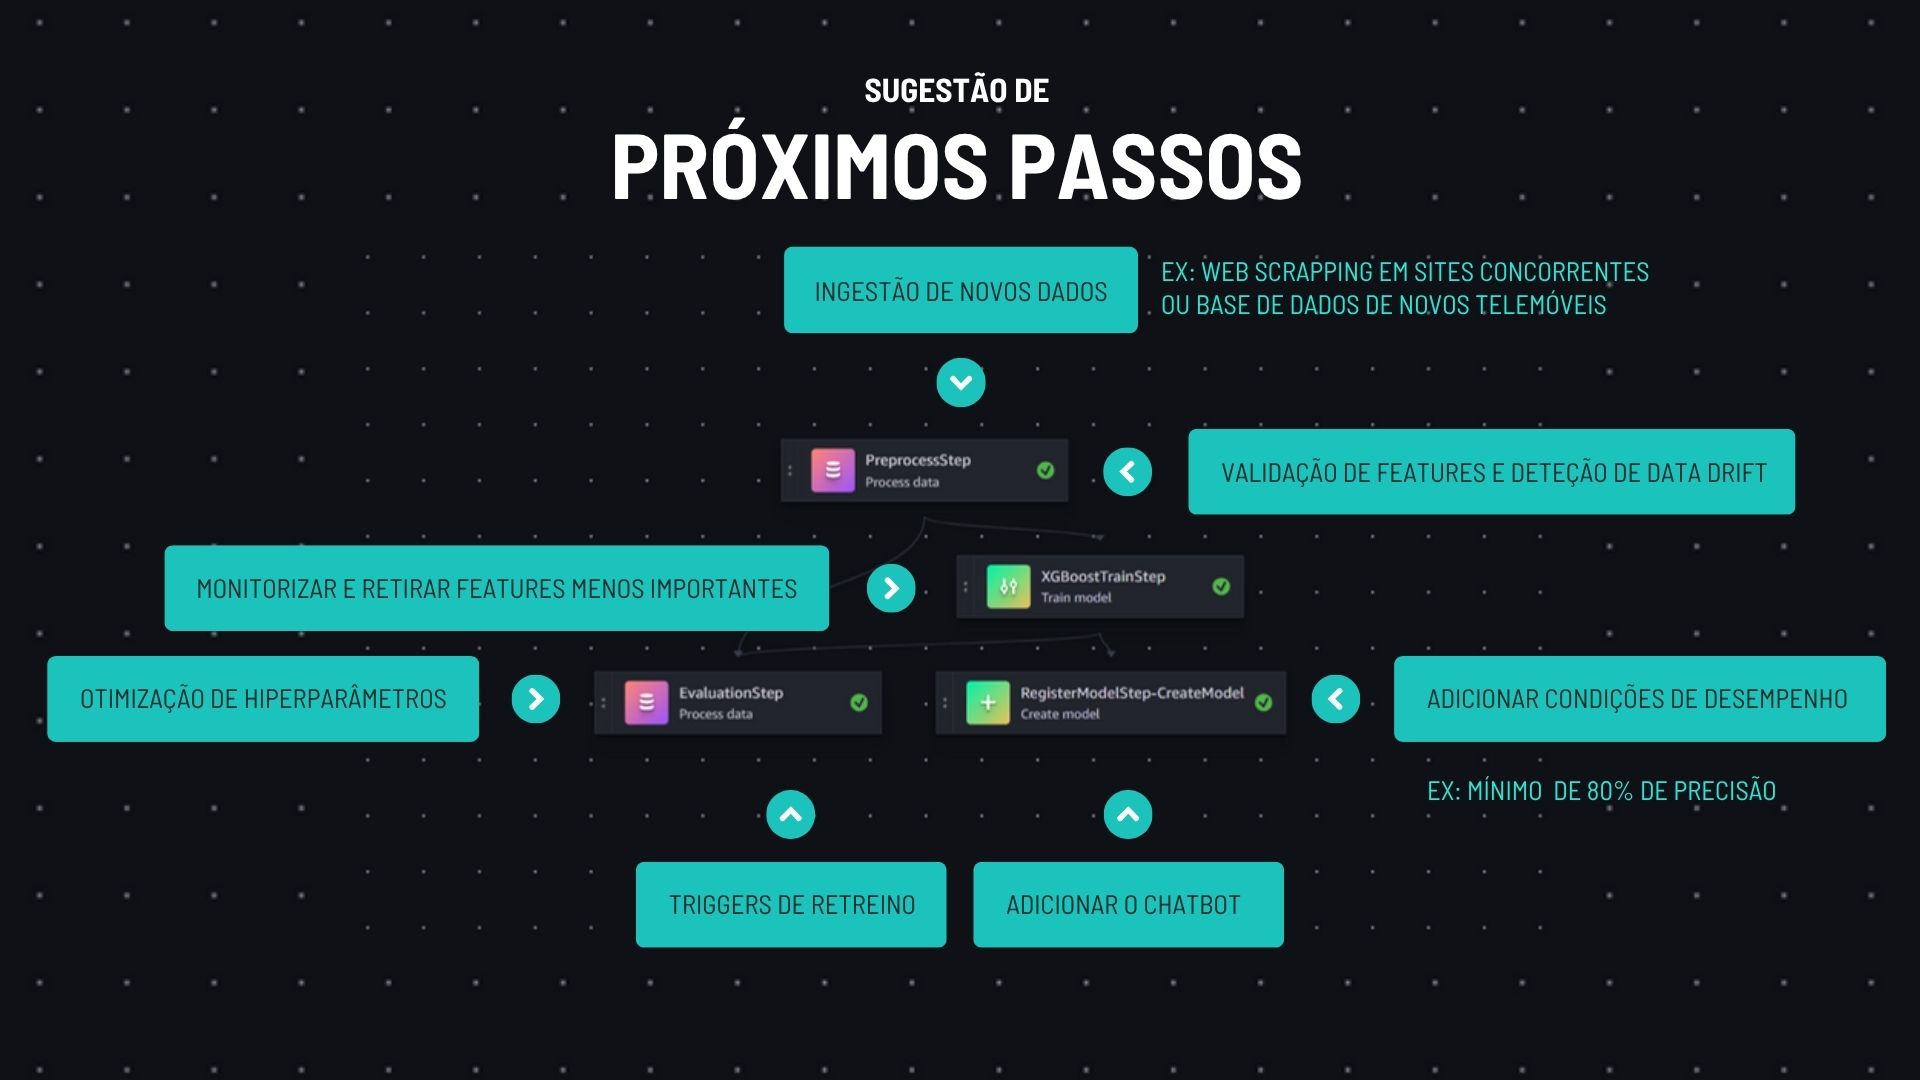

Contudo, este percurso não foi isento de desafios. Enfrentamos dilemas como o equilíbrio entre a experiência do utilizador e a qualidade do modelo, a complexidade da integração dos serviços AWS, e a constante tomada de decisões estratégicas sobre features e escalabilidade. Superar estes obstáculos foi fundamental para construir uma solução robusta e eficaz.